<a href="https://colab.research.google.com/github/ahmdalzbat34-code/-chest-xray-covid-ai-/blob/main/Copy_of_Untitled29.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# مشروع بحثي: الذكاء الاصطناعي لتحليل صور الأشعة السينية للصدر
# الخطوة 1: التحقق من بيئة Google Colab

استيراد  sys
استيراد  os
استيراد  platform

print ( "بحث: تحليل صور الأشعة السينية للصدر باستخدام الذكاء الاصطناعي" )
print ( "-"  *  45 )
print ( "إصدار بايثون: " ,  sys.version.split ()[ 0 ])
print ( "المنصة: " ,  platform.platform ())
print ( "دليل العمل: " ,  os.getcwd ())

# التحقق من توفر مكتبات البحث الشائعة lible
libraries =  [ "numpy" , "pandas" , "sklearn" , "PIL" , "torch" ]

for  library  in  libraries : try :         module =  __import__ ( library ) print ( f " { library } : available" ) except  ImportError : print ( f " { library } : not installed" )

Research: AI-Based Chest X-Ray Analysis
---------------------------------------------
Python version: 3.13.16
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
Working directory: /content
numpy: available
pandas: available
sklearn: available
PIL: available
torch: available


In [ ]:


import torch
import pandas as pd
import sklearn

print("=== Research Environment Check ===")
print("PyTorch:", torch.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

if torch.cuda.is_available():
    print("GPU: Available")
    print("GPU model:", torch.cuda.get_device_name(0))
else:
    print("GPU: Not enabled or unavailable")
    print("We can begin with lightweight data checks.")

print("Environment check completed.")

=== Research Environment Check ===
PyTorch: 2.11.0+cpu
Pandas: 2.2.3
Scikit-learn: 1.6.1
GPU: Not enabled or unavailable
We can begin with lightweight data checks.
Environment check completed.


In [ ]:

import pandas as pd
from pathlib import Path

# Prepare the research workspace
work_dir = Path("/content/chest_xray_research")
work_dir.mkdir(parents=True, exist_ok=True)

print("Research folder:", work_dir)
print("Folder created:", work_dir.exists())

# Check whether a dataset metadata file already exists
csv_files = list(Path("/content").glob("**/*.csv"))

print("\nCSV files currently available:", len(csv_files))

for file in csv_files[:10]:
    print(file)

Research folder: /content/chest_xray_research
Folder created: True

CSV files currently available: 4
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/mnist_test.csv


In [ ]:


import pandas as pd
from pathlib import Path
import urllib.request

research_dir = Path("/content/chest_xray_research")
csv_path = research_dir / "Data_Entry_2017.csv"

url = (
    "https://nihcc.app.box.com/"
    "shared/static/v8m4w8h2h7k9z5q3p6x1.csv"
)

print("Research folder:", research_dir)
print("Metadata file exists:", csv_path.exists())
print("Next step: obtain the official NIH metadata file.")
print("We will verify the source before downloading.")

Research folder: /content/chest_xray_research
Metadata file exists: False
Next step: obtain the official NIH metadata file.
We will verify the source before downloading.


In [ ]:


from pathlib import Path
import pandas as pd

research_dir = Path("/content/chest_xray_research")
research_dir.mkdir(parents=True, exist_ok=True)

# Locate the uploaded metadata file
candidates = list(Path("/content").rglob("Data_Entry_2017_v2020.csv"))

if not candidates:
    print("File not found yet. Please upload the CSV file to Colab.")
else:
    source = candidates[0]
    destination = research_dir / source.name

    if source.resolve() != destination.resolve():
        import shutil
        shutil.copy2(source, destination)

    df = pd.read_csv(destination)

    print("File loaded successfully!")
    print("Dataset shape:", df.shape)
    print("\nColumn names:")
    print(df.columns.tolist())
    print("\nFirst 5 rows:")
    display(df.head())
    print("\nNumber of unique images:",
          df["Image Index"].nunique() if "Image Index" in df.columns else "Check column names")

File loaded successfully!
Dataset shape: (112120, 11)

Column names:
['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Sex', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]']

First 5 rows:


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Sex,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y]
0,00000001_000.png,Cardiomegaly,0,1,57,M,PA,2682,2749,0.143,0.143
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168
3,00000002_000.png,No Finding,0,2,80,M,PA,2500,2048,0.171,0.171
4,00000003_001.png,Hernia,0,3,74,F,PA,2500,2048,0.168,0.168



Number of unique images: 112120


In [ ]:

import pandas as pd
from pathlib import Path
from collections import Counter

csv_path = Path("/content/chest_xray_research/Data_Entry_2017_v2020.csv")

df = pd.read_csv(csv_path)

# Basic dataset statistics
print("=== DATASET SUMMARY ===")
print("Total records:", len(df))
print("Unique image filenames:", df["Image Index"].nunique())
print("Unique patients:", df["Patient ID"].nunique())
print("Duplicate image filenames:", df["Image Index"].duplicated().sum())

# Count recorded findings
finding_counts = Counter()

for entry in df["Finding Labels"].dropna():
    for label in str(entry).split("|"):
        finding_counts[label.strip()] += 1

print("\n=== MOST FREQUENT FINDINGS ===")
for label, count in finding_counts.most_common(15):
    print(f"{label}: {count}")

# Patient and image characteristics
print("\n=== VIEW POSITION ===")
print(df["View Position"].value_counts(dropna=False))

print("\n=== PATIENT SEX ===")
print(df["Patient Sex"].value_counts(dropna=False))

print("\n=== AGE SUMMARY ===")
ages = pd.to_numeric(df["Patient Age"], errors="coerce")
print(ages.describe())

# Save findings for the research report
summary = pd.DataFrame(
    finding_counts.items(),
    columns=["Finding", "Record_Count"]
).sort_values("Record_Count", ascending=False)

summary.to_csv(
    "/content/chest_xray_research/finding_counts.csv",
    index=False
)

print("\nFinding counts saved successfully.")

=== DATASET SUMMARY ===
Total records: 112120
Unique image filenames: 112120
Unique patients: 30805
Duplicate image filenames: 0

=== MOST FREQUENT FINDINGS ===
No Finding: 60361
Infiltration: 19894
Effusion: 13317
Atelectasis: 11559
Nodule: 6331
Mass: 5782
Pneumothorax: 5302
Consolidation: 4667
Pleural_Thickening: 3385
Cardiomegaly: 2776
Emphysema: 2516
Edema: 2303
Fibrosis: 1686
Pneumonia: 1431
Hernia: 227

=== VIEW POSITION ===
View Position
PA    67310
AP    44810
Name: count, dtype: int64

=== PATIENT SEX ===
Patient Sex
M    63340
F    48780
Name: count, dtype: int64

=== AGE SUMMARY ===
count    112120.000000
mean         46.626365
std          16.602680
min           0.000000
25%          34.000000
50%          49.000000
75%          59.000000
max          95.000000
Name: Patient Age, dtype: float64

Finding counts saved successfully.


In [ ]:


استوردنا مكتبة  pandas  باسم  pd،
ومكتبة pathlib  باسم  Path  ، ومكتبة  sklearn.model_selection  باسم  GroupShuffleSplit.


csv_path = Path ( "/content/chest_xray_research/Data_Entry_2017_v202 0.csv" ) df = pd.read_csv ( csv_path )




# التقسيم حسب المريض، وليس حسب الصورة الفردية
splitter = GroupShuffleSplit (
    n_splits= 1 ,
    test_size= 0.20 ,
    random_state= 42
)

train_idx ,  test_idx =  next (
    splitter.split ( df ,  groups=df [ "Patient ID" ])
)

train_df = df.iloc [ train_idx ] .copy ()
test_df = df.iloc [ test_idx ] .copy ()

train_patients =  set ( train_df [ "Patient ID" ])
test_patients =  set ( test_df [ "Patient ID" ])

print ( "=== تقسيم على مستوى المريض ===" )
print ( "صور التدريب: " , len ( train_df ))
print ( "صور الاختبار: " , len ( test_df ))
print ( "مرضى التدريب: " , len ( train_patients ))
print ( "مرضى الاختبار: " , len ( test_patients ))
print ( "تداخل المرضى: " , len ( train_patients & test_patients ))

# التحقق من التصنيفات المحددة في كل مجموعة
: for  label  in [ "No Finding" , "Pneumonia" , "Effusion" , "Atelectasis" ]:     print ( f "\n { label } " ) for  name ,  part  in [( "Train" ,  train_df ), ( "Test" ,  test_df )]:         contains_label = part [ "Finding Labels" ] .fillna ( "" ) . str.split ( "|" ) .apply ( lambda  labels :  label  in  labels ) print (             name , "positive images:" , int ( contains_label.sum ( ) ), "percentage:" , round ( 100  * contains_label.mean (), 2 ) )











# حفظ بيانات التقسيم لضمان إمكانية إعادة الإنتاج
train_df [[ "Image Index" , "Patient ID" , "Finding Labels" ]] .to_csv (   "/content/chest_xray_research/train_manifest.csv" ,     index= False )




test_df [[ "Image Index" , "Patient ID" , "Finding Labels" ]] .to_csv (   "/content/chest_xray_research/test_manifest.csv" ,     index= False )




print ( "\nتم حفظ بيانات التقسيم." )

=== PATIENT-LEVEL SPLIT ===
Training images: 89826
Testing images: 22294
Training patients: 24644
Testing patients: 6161
Patient overlap: 0

No Finding
Train positive images: 48373 percentage: 53.85
Test positive images: 11988 percentage: 53.77

Pneumonia
Train positive images: 1137 percentage: 1.27
Test positive images: 294 percentage: 1.32

Effusion
Train positive images: 10764 percentage: 11.98
Test positive images: 2553 percentage: 11.45

Atelectasis
Train positive images: 9352 percentage: 10.41
Test positive images: 2207 percentage: 9.9

Split manifests saved.


In [ ]:


import os
import pandas as pd

ROOT = "/content"

# البحث عن ملفات التقسيم المحفوظة
manifest_files = []

for root, dirs, files in os.walk(ROOT):
    # تجاهل مجلدات النظام المؤقتة إن وجدت
    dirs[:] = [d for d in dirs if d not in [".cache", "__pycache__"]]

    for file in files:
        name = file.lower()
        if (
            ("split" in name or "manifest" in name)
            and name.endswith((".csv", ".parquet", ".json"))
        ):
            manifest_files.append(os.path.join(root, file))

print("عدد ملفات التقسيم التي تم العثور عليها:", len(manifest_files))

for path in manifest_files:
    print("\n" + "=" * 60)
    print("الملف:", path)

    try:
        if path.endswith(".csv"):
            df = pd.read_csv(path, nrows=5)
        elif path.endswith(".parquet"):
            df = pd.read_parquet(path).head(5)
        else:
            df = pd.read_json(path).head(5)

        print("الأعمدة:", df.columns.tolist())
        print(df.to_string(index=False))

    except Exception as e:
        print("تعذر قراءة الملف:", str(e))

عدد ملفات التقسيم التي تم العثور عليها: 0


In [ ]:

استيراد  نظام التشغيل

طباعة ( "المجلدات والملفات الموجودة داخل /المحتوى:\n" )

for  name  in  os.listdir ( "/content" ):
    path = os.path.join ( "/content" ,  name )

    إذا كان المسار مجلدًا (  os.path.isdir ( path )): اطبع ( "📁" ,  name ) حاول : لكل  عنصر  في قائمة المجلدات (  os.listdir ( path ))[: 10 ]: اطبع ( " " ,  item ) باستثناء  استثناء : مرر وإلا : اطبع ( "📄" ,  name )

المجلدات والملفات الموجودة داخل /content:

📁 .config
    active_config
    default_configs.db
    hidden_gcloud_config_universe_descriptor_data_cache_configs.db
    gce
    config_sentinel
    logs
    .last_update_check.json
    .last_opt_in_prompt.yaml
    configurations
    .last_survey_prompt.yaml
📁 sample_data
    anscombe.json
    README.md
    california_housing_test.csv
    mnist_train_small.csv
    california_housing_train.csv
    mnist_test.csv


In [ ]:


from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

import os

base = "/content/drive/MyDrive"

print("محتويات Google Drive:\n")

for name in os.listdir(base):
    path = os.path.join(base, name)

    if os.path.isdir(path):
        print("📁", name)
    else:
        print("📄", name)

محتويات Google Drive:

📁 Colab Notebooks
📄 جدول بيانات بلا عنوان.gsheet
📄 Untitled Diagram.drawio 123.jpg
📁 مجلد بلا عنوان
📄 Untitled Diagram.drawio 123.drawio.pdf
📄 ahmed.drawio.pdf
📄 Untitled Diagram.drawio 123
📄 IMG_20240120_154114_80.jpg
📄 AI_Assisted_Autonomous_Portable_XRay_Concept_Paper.pdf
📄 ‏مستند من ابو ميرا.pdf


In [ ]:

import os

folder = "/content/drive/MyDrive/مجلد بلا عنوان"

for root, dirs, files in os.walk(folder):
    level = root.replace(folder, "").count(os.sep)
    indent = "  " * level

    print(f"{indent}📁 {os.path.basename(root)}/")

    for name in files[:20]:
        print(f"{indent}  📄 {name}")

print("\nانتهى فحص المجلد.")

📁 مجلد بلا عنوان/
  📄 New Text Document.txt
  📄 New Text Document ahmed.txt

انتهى فحص المجلد.


In [ ]:

import os

folder = "/content/drive/MyDrive/Colab Notebooks"

for root, dirs, files in os.walk(folder):
    print("\n📁", root)
    for name in files:
        print("  📄", name)


📁 /content/drive/MyDrive/Colab Notebooks
  📄 Untitled29.ipynb
  📄 Untitled (2)
  📄 Untitled0.ipynb
  📄 Untitled1.ipynb
  📄 Untitled2.ipynb
  📄 Untitled3.ipynb
  📄 Untitled4.ipynb
  📄 Untitled5.ipynb
  📄 Untitled6.ipynb
  📄 Untitled7.ipynb
  📄 Untitled8.ipynb
  📄 Untitled9.ipynb
  📄 Untitled10.ipynb
  📄 Untitled11.ipynb
  📄 Untitled12.ipynb
  📄 Untitled13.ipynb
  📄 Untitled14.ipynb
  📄 Untitled15.ipynb
  📄 Untitled16.ipynb
  📄 Untitled17.ipynb
  📄 Untitled18.ipynb
  📄 Untitled19.ipynb
  📄 Untitled20.ipynb
  📄 Untitled21.ipynb
  📄 Untitled22.ipynb
  📄 Untitled23.ipynb
  📄 Untitled24.ipynb
  📄 Untitled (1)
  📄 Untitled
  📄 Untitled25.ipynb
  📄 Untitled26.ipynb
  📄 Untitled27.ipynb
  📄 Untitled28.ipynb


In [ ]:


import os
import json

base = "/content/drive/MyDrive/Colab Notebooks"

keywords = [
    "PATIENT-LEVEL SPLIT",
    "Split manifests saved",
    "Pneumonia",
    "Effusion",
    "patient_id",
    "Chest X-Ray",
    "89826",
    "22294"
]

for filename in os.listdir(base):
    path = os.path.join(base, filename)

    if not filename.endswith(".ipynb"):
        continue

    try:
        with open(path, "r", encoding="utf-8") as f:
            notebook = json.load(f)

        matches = []

        for cell in notebook.get("cells", []):
            source = "".join(cell.get("source", []))

            for keyword in keywords:
                if keyword.lower() in source.lower():
                    matches.append(keyword)

        if matches:
            print("دفتر:", filename)
            print("الكلمات الموجودة:", ", ".join(sorted(set(matches))))
            print("-" * 40)

    except Exception as e:
        print("تعذر فحص:", filename, str(e))

دفتر: Untitled29.ipynb
الكلمات الموجودة: Chest X-Ray, Effusion, Pneumonia
----------------------------------------


In [ ]:

import json
import os

path = "/content/drive/MyDrive/Colab Notebooks/Untitled29.ipynb"

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

terms = [
    "PATIENT-LEVEL SPLIT",
    "Split manifests saved",
    "patient overlap",
    "train_df",
    "test_df",
    "manifest",
    "Pneumonia",
    "Effusion"
]

print("عدد الخلايا:", len(nb.get("cells", [])))

for i, cell in enumerate(nb.get("cells", [])):
    source = "".join(cell.get("source", []))
    outputs = "\n".join(
        "".join(out.get("text", []))
        if isinstance(out.get("text"), list)
        else str(out.get("text", ""))
        for out in cell.get("outputs", [])
    )

    combined = source + "\n" + outputs

    if any(term.lower() in combined.lower() for term in terms):
        print("\n" + "=" * 60)
        print("رقم الخلية:", i, "| النوع:", cell.get("cell_type"))
        print("الكود:")
        print(source[:1800])
        if outputs.strip():
            print("\nالمخرجات:")
            print(outputs[:1200])

عدد الخلايا: 18

رقم الخلية: 8 | النوع: code
الكود:

import pandas as pd
from pathlib import Path
from collections import Counter

csv_path = Path("/content/chest_xray_research/Data_Entry_2017_v2020.csv")

df = pd.read_csv(csv_path)

# Basic dataset statistics
print("=== DATASET SUMMARY ===")
print("Total records:", len(df))
print("Unique image filenames:", df["Image Index"].nunique())
print("Unique patients:", df["Patient ID"].nunique())
print("Duplicate image filenames:", df["Image Index"].duplicated().sum())

# Count recorded findings
finding_counts = Counter()

for entry in df["Finding Labels"].dropna():
    for label in str(entry).split("|"):
        finding_counts[label.strip()] += 1

print("\n=== MOST FREQUENT FINDINGS ===")
for label, count in finding_counts.most_common(15):
    print(f"{label}: {count}")

# Patient and image characteristics
print("\n=== VIEW POSITION ===")
print(df["View Position"].value_counts(dropna=False))

print("\n=== PATIENT SEX ===")
print(df["Patient S

In [ ]:

import json

path = "/content/drive/MyDrive/Colab Notebooks/Untitled29.ipynb"

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

terms = [
    "PATIENT-LEVEL SPLIT",
    "Training images:",
    "Testing images:",
    "Patient overlap:",
    "Split manifests saved"
]

found = False

for i, cell in enumerate(nb["cells"]):
    for out in cell.get("outputs", []):
        text = ""

        if "text" in out:
            text = "".join(out["text"])
        elif "data" in out:
            text = str(out["data"].get("text/plain", ""))

        if any(term.lower() in text.lower() for term in terms):
            print("الخلية رقم:", i)
            print(text[:2500])
            found = True

if not found:
    print("لم نجد نتائج التقسيم محفوظة في مخرجات هذا الدفتر.")

الخلية رقم: 9
=== PATIENT-LEVEL SPLIT ===
Training images: 89826
Testing images: 22294
Training patients: 24644
Testing patients: 6161
Patient overlap: 0

No Finding
Train positive images: 48373 percentage: 53.85
Test positive images: 11988 percentage: 53.77

Pneumonia
Train positive images: 1137 percentage: 1.27
Test positive images: 294 percentage: 1.32

Effusion
Train positive images: 10764 percentage: 11.98
Test positive images: 2553 percentage: 11.45

Atelectasis
Train positive images: 9352 percentage: 10.41
Test positive images: 2207 percentage: 9.9

Split manifests saved.

الخلية رقم: 18
عدد الخلايا: 18

رقم الخلية: 8 | النوع: code
الكود:

import pandas as pd
from pathlib import Path
from collections import Counter

csv_path = Path("/content/chest_xray_research/Data_Entry_2017_v2020.csv")

df = pd.read_csv(csv_path)

# Basic dataset statistics
print("=== DATASET SUMMARY ===")
print("Total records:", len(df))
print("Unique image filenames:", df["Image Index"].nunique())
print("Un

In [ ]:

import json

path = "/content/drive/MyDrive/Colab Notebooks/Untitled29.ipynb"

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"][:10]):
    if cell.get("cell_type") == "code":
        source = "".join(cell.get("source", []))
        print("\n" + "=" * 45)
        print("CELL", i)
        print(source[:1800])


CELL 0

# Research project: AI for chest X-ray analysis
# Step 1: Check the Google Colab environment

import sys
import os
import platform

print("Research: AI-Based Chest X-Ray Analysis")
print("-" * 45)
print("Python version:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Working directory:", os.getcwd())

# Check whether common research libraries are available
libraries = ["numpy", "pandas", "sklearn", "PIL", "torch"]

for library in libraries:
    try:
        module = __import__(library)
        print(f"{library}: available")
    except ImportError:
        print(f"{library}: not installed")

CELL 1


import torch
import pandas as pd
import sklearn

print("=== Research Environment Check ===")
print("PyTorch:", torch.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

if torch.cuda.is_available():
    print("GPU: Available")
    print("GPU model:", torch.cuda.get_device_name(0))
else:
    print("GPU: Not enabled or u

In [ ]:

import os

base = "/content/drive/MyDrive"

targets = {
    "data_entry_2017_v2020.csv",
    "train_manifest.csv",
    "test_manifest.csv"
}

print("جارٍ البحث عن ملفات المشروع...\n")

found = []

for root, dirs, files in os.walk(base):
    dirs[:] = [d for d in dirs if d not in [".Trash"]]

    for filename in files:
        if filename.lower() in targets:
            path = os.path.join(root, filename)
            found.append(path)
            print("تم العثور على:", path)

if not found:
    print("لم يتم العثور على ملفات البيانات أو التقسيم في Google Drive.")

جارٍ البحث عن ملفات المشروع...

لم يتم العثور على ملفات البيانات أو التقسيم في Google Drive.


In [ ]:

import os

paths = [
    "/content/chest_xray_research/Data_Entry_2017_v2020.csv",
    "/content/chest_xray_research/train_manifest.csv",
    "/content/chest_xray_research/test_manifest.csv"
]

for path in paths:
    print(("موجود ✅ " if os.path.isfile(path) else "غير موجود ❌ ") + path)

غير موجود ❌ /content/chest_xray_research/Data_Entry_2017_v2020.csv
غير موجود ❌ /content/chest_xray_research/train_manifest.csv
غير موجود ❌ /content/chest_xray_research/test_manifest.csv


In [ ]:

import shutil

total, used, free = shutil.disk_usage("/content")

print(f"المساحة الكلية: {total / (1024**3):.2f} GB")
print(f"المساحة المستخدمة: {used / (1024**3):.2f} GB")
print(f"المساحة المتاحة: {free / (1024**3):.2f} GB")

المساحة الكلية: 107.72 GB
المساحة المستخدمة: 20.50 GB
المساحة المتاحة: 87.20 GB


In [ ]:


import os
import requests

save_dir = "/content/drive/MyDrive/chest_xray_research"
os.makedirs(save_dir, exist_ok=True)

url = "https://raw.githubusercontent.com/ieee8023/covid-chestxray-dataset/master/metadata.csv"
save_path = os.path.join(save_dir, "metadata.csv")

response = requests.get(url, timeout=60)

if response.status_code == 200 and len(response.content) > 1000:
    with open(save_path, "wb") as f:
        f.write(response.content)

    print("تم تنزيل الملف:", save_path)
    print("حجم الملف:", round(len(response.content) / 1024, 2), "KB")
    print("تنبيه: هذا ملف بيانات لمجموعة مختلفة، وليس ملف NIH المطلوب.")
else:
    print("لم ينجح التنزيل. رمز الاستجابة:", response.status_code)

تم تنزيل الملف: /content/drive/MyDrive/chest_xray_research/metadata.csv
حجم الملف: 585.1 KB
تنبيه: هذا ملف بيانات لمجموعة مختلفة، وليس ملف NIH المطلوب.


In [ ]:


import os
import requests

save_dir = "/content/drive/MyDrive/chest_xray_research"
os.makedirs(save_dir, exist_ok=True)

url = "https://raw.githubusercontent.com/ieee8023/covid-chestxray-dataset/master/metadata.csv"
save_path = os.path.join(save_dir, "metadata.csv")

response = requests.get(url, timeout=60)

if response.status_code == 200 and len(response.content) > 1000:
    with open(save_path, "wb") as f:
        f.write(response.content)

    print("تم تنزيل الملف:", save_path)
    print("حجم الملف:", round(len(response.content) / 1024, 2), "KB")
    print("تنبيه: هذا ملف بيانات لمجموعة مختلفة، وليس ملف NIH المطلوب.")
else:
    print("لم ينجح التنزيل. رمز الاستجابة:", response.status_code)

تم تنزيل الملف: /content/drive/MyDrive/chest_xray_research/metadata.csv
حجم الملف: 585.1 KB
تنبيه: هذا ملف بيانات لمجموعة مختلفة، وليس ملف NIH المطلوب.


In [ ]:


import pandas as pd

path = "/content/drive/MyDrive/chest_xray_research/metadata.csv"

df_check = pd.read_csv(path)

print("عدد الصفوف:", len(df_check))
print("الأعمدة:")
print(df_check.columns.tolist())

if {"Image Index", "Patient ID", "Finding Labels"}.issubset(df_check.columns):
    print("\nهذا الملف يحتوي على الأعمدة المطلوبة.")
else:
    print("\nهذا ليس ملف NIH الأصلي المطلوب لمشروعنا.")

عدد الصفوف: 950
الأعمدة:
['patientid', 'offset', 'sex', 'age', 'finding', 'RT_PCR_positive', 'survival', 'intubated', 'intubation_present', 'went_icu', 'in_icu', 'needed_supplemental_O2', 'extubated', 'temperature', 'pO2_saturation', 'leukocyte_count', 'neutrophil_count', 'lymphocyte_count', 'view', 'modality', 'date', 'location', 'folder', 'filename', 'doi', 'url', 'license', 'clinical_notes', 'other_notes', 'Unnamed: 29']

هذا ليس ملف NIH الأصلي المطلوب لمشروعنا.


In [ ]:
import os

from google.colab import drive
drive.mount('/content/drive')

folder = '/content/drive/MyDrive/chest_xray_research'

print("هل مجلد المشروع موجود؟", os.path.exists(folder))

if os.path.exists(folder):
    print("\nالملفات الموجودة داخل المجلد:")
    for f in os.listdir(folder):
        print(f)
else:
    print("مجلد المشروع غير موجود على Google Drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
هل مجلد المشروع موجود؟ True

الملفات الموجودة داخل المجلد:
metadata.csv


In [ ]:
import os

root = "/content/drive/MyDrive"
targets = {
    "Data_Entry_2017.csv",
    "Data_Entry_2017_v2020.csv",
    "train_manifest.csv",
    "test_manifest.csv"
}

for folder, dirs, files in os.walk(root):
    dirs[:] = [d for d in dirs if d not in [".ipynb_checkpoints"]]
    for filename in files:
        if filename in targets:
            print(os.path.join(folder, filename))

In [ ]:

import os

root = "/content/drive/MyDrive"
targets = {
    "Data_Entry_2017.csv",
    "Data_Entry_2017_v2020.csv",
    "train_manifest.csv",
    "test_manifest.csv"
}

for folder, dirs, files in os.walk(root):
    dirs[:] = [d for d in dirs if d not in [".ipynb_checkpoints"]]
    for filename in files:
        if filename in targets:
            print(os.path.join(folder, filename))

In [ ]:
import os

base = "/content/drive/MyDrive"

print("=== مجلد المشروع ===")
folder = os.path.join(base, "chest_xray_research")

if os.path.exists(folder):
    print(os.listdir(folder))

print("\n=== دفاتر Colab ===")
notebooks = os.path.join(base, "Colab Notebooks")

if os.path.exists(notebooks):
    for f in os.listdir(notebooks):
        if f.endswith(".ipynb"):
            print(f)

=== مجلد المشروع ===
['metadata.csv']

=== دفاتر Colab ===
Untitled29.ipynb
Untitled0.ipynb
Untitled1.ipynb
Untitled2.ipynb
Untitled3.ipynb
Untitled4.ipynb
Untitled5.ipynb
Untitled6.ipynb
Untitled7.ipynb
Untitled8.ipynb
Untitled9.ipynb
Untitled10.ipynb
Untitled11.ipynb
Untitled12.ipynb
Untitled13.ipynb
Untitled14.ipynb
Untitled15.ipynb
Untitled16.ipynb
Untitled17.ipynb
Untitled18.ipynb
Untitled19.ipynb
Untitled20.ipynb
Untitled21.ipynb
Untitled22.ipynb
Untitled23.ipynb
Untitled24.ipynb
Untitled25.ipynb
Untitled26.ipynb
Untitled27.ipynb
Untitled28.ipynb


In [ ]:
import json
import os

path = "/content/drive/MyDrive/Colab Notebooks/Untitled29.ipynb"

with open(path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

print("عدد خلايا الدفتر:", len(notebook["cells"]))
print("\n=== آخر الخلايا ونتائجها ===")

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell.get("source", []))
        outputs = cell.get("outputs", [])

        if any(x in source.lower() for x in [
            "train_manifest",
            "test_manifest",
            "patient-level split",
            "data_entry_2017"
        ]):
            print(f"\n--- الخلية {i} ---")
            print(source[:1200])

            for output in outputs:
                text = output.get("text", [])
                if text:
                    print("".join(text)[:1500])

                for item in output.get("data", {}).values():
                    if "text/plain" in item:
                        print("".join(item["text/plain"])[:1500])

عدد خلايا الدفتر: 31

=== آخر الخلايا ونتائجها ===

--- الخلية 3 ---


import pandas as pd
from pathlib import Path
import urllib.request

research_dir = Path("/content/chest_xray_research")
csv_path = research_dir / "Data_Entry_2017.csv"

url = (
    "https://nihcc.app.box.com/"
    "shared/static/v8m4w8h2h7k9z5q3p6x1.csv"
)

print("Research folder:", research_dir)
print("Metadata file exists:", csv_path.exists())
print("Next step: obtain the official NIH metadata file.")
print("We will verify the source before downloading.")
Research folder: /content/chest_xray_research
Metadata file exists: False
Next step: obtain the official NIH metadata file.
We will verify the source before downloading.


--- الخلية 7 ---


from pathlib import Path
import pandas as pd

research_dir = Path("/content/chest_xray_research")
research_dir.mkdir(parents=True, exist_ok=True)

# Locate the uploaded metadata file
candidates = list(Path("/content").rglob("Data_Entry_2017_v2020.csv"))

if not candidates:
  

In [ ]:
import os

for base in ["/content", "/content/drive/MyDrive"]:
    print(f"\n=== البحث داخل {base} ===")

    for root, dirs, files in os.walk(base):
        dirs[:] = [
            d for d in dirs
            if d not in [".ipynb_checkpoints", ".Trash"]
        ]

        for f in files:
            name = f.lower()

            if (
                "data_entry" in name
                or "train_manifest" in name
                or "test_manifest" in name
                or "chestxray" in name
            ):
                print(os.path.join(root, f))


=== البحث داخل /content ===

=== البحث داخل /content/drive/MyDrive ===


In [ ]:

import os

print("الملفات الموجودة في Colab:")
for name in os.listdir("/content"):
    path = os.path.join("/content", name)
    size_mb = (
        os.path.getsize(path) / (1024 * 1024)
        if os.path.isfile(path) else 0
    )
    print(f"{name} — {size_mb:.1f} MB" if os.path.isfile(path) else f"{name} — مجلد")

الملفات الموجودة في Colab:
.config — مجلد
drive — مجلد
sample_data — مجلد


In [ ]:
import os

folder = "/content/drive/MyDrive"

for name in os.listdir(folder):
    path = os.path.join(folder, name)

    if os.path.isfile(path):
        size = os.path.getsize(path) / (1024**3)
        print(f"📄 {name} — {size:.2f} GB")
    else:
        print(f"📁 {name}/")

📁 Colab Notebooks/
📄 جدول بيانات بلا عنوان.gsheet — 0.00 GB
📄 Untitled Diagram.drawio 123.jpg — 0.00 GB
📁 مجلد بلا عنوان/
📄 Untitled Diagram.drawio 123.drawio.pdf — 0.00 GB
📄 ahmed.drawio.pdf — 0.00 GB
📄 Untitled Diagram.drawio 123 — 0.00 GB
📄 IMG_20240120_154114_80.jpg — 0.00 GB
📄 AI_Assisted_Autonomous_Portable_XRay_Concept_Paper.pdf — 0.00 GB
📄 ‏مستند من ابو ميرا.pdf — 0.00 GB
📁 chest_xray_research/


In [ ]:
import os

folder = "/content/drive/MyDrive/chest_xray_research"

print("محتويات مجلد المشروع:")
for name in os.listdir(folder):
    path = os.path.join(folder, name)

    if os.path.isfile(path):
        size = os.path.getsize(path) / (1024**3)
        print(f"📄 {name} — {size:.3f} GB")
    else:
        print(f"📁 {name}/")

محتويات مجلد المشروع:
📄 metadata.csv — 0.001 GB


In [ ]:
from pathlib import Path
import pandas as pd

folder = Path("/content/drive/MyDrive/chest_xray_research")
folder.mkdir(parents=True, exist_ok=True)

results = [
    ["Total images", 112120],
    ["Unique patients", 30805],
    ["Training images (previous run)", 89826],
    ["Testing images (previous run)", 22294],
    ["Training patients (previous run)", 24644],
    ["Testing patients (previous run)", 6161],
    ["Patient overlap (previous run)", 0],
    ["Pneumonia - training positive images", 1137],
    ["Pneumonia - testing positive images", 294],
    ["Effusion - training positive images", 10764],
    ["Effusion - testing positive images", 2553],
    ["Atelectasis - training positive images", 9352],
    ["Atelectasis - testing positive images", 2207],
]

df_results = pd.DataFrame(
    results, columns=["Metric", "Value"]
)

output = folder / "recovered_previous_results.csv"
df_results.to_csv(output, index=False)

print("تم حفظ ملخص النتائج السابقة في:")
print(output)
print("\nعدد النتائج المحفوظة:", len(df_results))
print("\n", df_results.to_string(index=False))

تم حفظ ملخص النتائج السابقة في:
/content/drive/MyDrive/chest_xray_research/recovered_previous_results.csv

عدد النتائج المحفوظة: 13

                                 Metric  Value
                          Total images 112120
                       Unique patients  30805
        Training images (previous run)  89826
         Testing images (previous run)  22294
      Training patients (previous run)  24644
       Testing patients (previous run)   6161
        Patient overlap (previous run)      0
  Pneumonia - training positive images   1137
   Pneumonia - testing positive images    294
   Effusion - training positive images  10764
    Effusion - testing positive images   2553
Atelectasis - training positive images   9352
 Atelectasis - testing positive images   2207


In [ ]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/chest_xray_research")

report = """
# Chest X-ray AI Research
## Preliminary Dataset Analysis and Patient-Level Split

### Dataset overview
The previously analyzed NIH ChestX-ray14 metadata contained
112,120 image records from 30,805 unique patients.

### Patient-level data split
The previous analysis recorded:
- Training images: 89,826
- Testing images: 22,294
- Training patients: 24,644
- Testing patients: 6,161
- Patient overlap: 0

The split was performed by grouping records by Patient ID,
using GroupShuffleSplit with test_size=0.20 and random_state=42.

### Selected findings
- Pneumonia: 1,137 training records and 294 testing records.
- Effusion: 10,764 training records and 2,553 testing records.
- Atelectasis: 9,352 training records and 2,207 testing records.

### Interpretation and limitations
The recorded patient-level split had no patient overlap.
This helps reduce data leakage between training and testing sets.

These are results preserved from a previous analysis.
The original metadata and split files are not currently available
in the project folder, so the results have not yet been independently
reproduced in the current session.

No model training performance, accuracy, sensitivity, specificity,
or AUC is claimed in this report.
"""

path = folder / "preliminary_results_report.md"
path.write_text(report, encoding="utf-8")

print("تم حفظ التقرير:")
print(path)

تم حفظ التقرير:
/content/drive/MyDrive/chest_xray_research/preliminary_results_report.md


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os

folders = [
    "/content/drive/MyDrive/chest_xray_research",
    "/content/drive/MyDrive/Colab Notebooks"
]

for folder in folders:
    print(f"\n📁 {folder}")
    if os.path.exists(folder):
        for name in os.listdir(folder)[:40]:
            path = os.path.join(folder, name)
            kind = "مجلد" if os.path.isdir(path) else "ملف"
            print(f"  {kind}: {name}")
    else:
        print("المجلد غير موجود")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

📁 /content/drive/MyDrive/chest_xray_research
  ملف: metadata.csv
  ملف: recovered_previous_results.csv
  ملف: preliminary_results_report.md

📁 /content/drive/MyDrive/Colab Notebooks
  ملف: Untitled29.ipynb
  ملف: Untitled (2)
  ملف: Untitled0.ipynb
  ملف: Untitled1.ipynb
  ملف: Untitled2.ipynb
  ملف: Untitled3.ipynb
  ملف: Untitled4.ipynb
  ملف: Untitled5.ipynb
  ملف: Untitled6.ipynb
  ملف: Untitled7.ipynb
  ملف: Untitled8.ipynb
  ملف: Untitled9.ipynb
  ملف: Untitled10.ipynb
  ملف: Untitled11.ipynb
  ملف: Untitled12.ipynb
  ملف: Untitled13.ipynb
  ملف: Untitled14.ipynb
  ملف: Untitled15.ipynb
  ملف: Untitled16.ipynb
  ملف: Untitled17.ipynb
  ملف: Untitled18.ipynb
  ملف: Untitled19.ipynb
  ملف: Untitled20.ipynb
  ملف: Untitled21.ipynb
  ملف: Untitled22.ipynb
  ملف: Untitled23.ipynb
  ملف: Untitled24.ipynb
  ملف: Untitled (1)
  ملف: Untitled
  ملف: Untitled25.

In [ ]:

import os
import pandas as pd

path = "/content/drive/MyDrive/chest_xray_research/metadata.csv"

df = pd.read_csv(path)

print("عدد الصفوف والأعمدة:", df.shape)
print("\nأسماء الأعمدة:")
print(df.columns.tolist())

print("\nأول 5 صفوف:")
display(df.head())

print("\nحجم الملف:")
print(f"{os.path.getsize(path) / (1024**2):.2f} MB")

# فحص بعض الأعمدة المهمة إن كانت موجودة
for col in ["Patient ID", "Image Index", "Finding Labels", "patient_id", "labels"]:
    if col in df.columns:
        print(f"\nالقيم في العمود {col}:")
        print(df[col].head(10).to_list())

عدد الصفوف والأعمدة: (950, 30)

أسماء الأعمدة:
['patientid', 'offset', 'sex', 'age', 'finding', 'RT_PCR_positive', 'survival', 'intubated', 'intubation_present', 'went_icu', 'in_icu', 'needed_supplemental_O2', 'extubated', 'temperature', 'pO2_saturation', 'leukocyte_count', 'neutrophil_count', 'lymphocyte_count', 'view', 'modality', 'date', 'location', 'folder', 'filename', 'doi', 'url', 'license', 'clinical_notes', 'other_notes', 'Unnamed: 29']

أول 5 صفوف:


,patientid,offset,sex,age,finding,RT_PCR_positive,survival,intubated,intubation_present,went_icu,...,date,location,folder,filename,doi,url,license,clinical_notes,other_notes,Unnamed: 29
0,2,0.0,M,65.0,Pneumonia/Viral/COVID-19,Y,Y,N,N,N,...,"January 22, 2020","Cho Ray Hospital, Ho Chi Minh City, Vietnam",images,auntminnie-a-2020_01_28_23_51_6665_2020_01_28_...,10.1056/nejmc2001272,https://www.nejm.org/doi/full/10.1056/NEJMc200...,NaN,"On January 22, 2020, a 65-year-old man with a ...",NaN,NaN
1,2,3.0,M,65.0,Pneumonia/Viral/COVID-19,Y,Y,N,N,N,...,"January 25, 2020","Cho Ray Hospital, Ho Chi Minh City, Vietnam",images,auntminnie-b-2020_01_28_23_51_6665_2020_01_28_...,10.1056/nejmc2001272,https://www.nejm.org/doi/full/10.1056/NEJMc200...,NaN,"On January 22, 2020, a 65-year-old man with a ...",NaN,NaN
2,2,5.0,M,65.0,Pneumonia/Viral/COVID-19,Y,Y,N,N,N,...,"January 27, 2020","Cho Ray Hospital, Ho Chi Minh City, Vietnam",images,auntminnie-c-2020_01_28_23_51_6665_2020_01_28_...,10.1056/nejmc2001272,https://www.nejm.org/doi/full/10.1056/NEJMc200...,NaN,"On January 22, 2020, a 65-year-old man with a ...",NaN,NaN
3,2,6.0,M,65.0,Pneumonia/Viral/COVID-19,Y,Y,N,N,N,...,"January 28, 2020","Cho Ray Hospital, Ho Chi Minh City, Vietnam",images,auntminnie-d-2020_01_28_23_51_6665_2020_01_28_...,10.1056/nejmc2001272,https://www.nejm.org/doi/full/10.1056/NEJMc200...,NaN,"On January 22, 2020, a 65-year-old man with a ...",NaN,NaN
4,4,0.0,F,52.0,Pneumonia/Viral/COVID-19,Y,NaN,N,N,N,...,"January 25, 2020","Changhua Christian Hospital, Changhua City, Ta...",images,nejmc2001573_f1a.jpeg,10.1056/NEJMc2001573,https://www.nejm.org/doi/full/10.1056/NEJMc200...,NaN,diffuse infiltrates in the bilateral lower lungs,NaN,NaN



حجم الملف:
0.57 MB


In [ ]:

import os
import pandas as pd

base = "/content/drive/MyDrive/chest_xray_research"
df = pd.read_csv(os.path.join(base, "metadata.csv"))

# عرض عدد الحالات والتصنيفات
print("عدد السجلات:", len(df))
print("\nأكثر التصنيفات:")
print(df["finding"].value_counts().head(15))

# فحص أسماء الصور في مجلد المشروع
image_ext = (".png", ".jpg", ".jpeg", ".webp")
found_images = []

for root, dirs, files in os.walk(base):
    for name in files:
        if name.lower().endswith(image_ext):
            found_images.append(os.path.join(root, name))

print("\nعدد ملفات الصور الموجودة داخل مجلد المشروع:", len(found_images))
print("\nأمثلة على الصور:", found_images[:10])

# فحص وجود الصور بالاسم المسجل في البيانات
if "filename" in df.columns:
    available_names = {os.path.basename(p) for p in found_images}
    df["image_exists"] = df["filename"].fillna("").map(
        lambda x: os.path.basename(str(x)) in available_names
        if x else False
    )
    print("\nالصور المطابقة للسجلات:", int(df["image_exists"].sum()))
    print("الصور غير الموجودة:", int((~df["image_exists"]).sum()))

عدد السجلات: 950

أكثر التصنيفات:
finding
Pneumonia/Viral/COVID-19             584
todo                                  83
Pneumonia                             81
Pneumonia/Fungal/Pneumocystis         30
Pneumonia/Bacterial/Streptococcus     22
No Finding                            22
Tuberculosis                          18
Pneumonia/Viral/SARS                  16
Pneumonia/Lipoid                      13
Pneumonia/Bacterial/Mycoplasma        11
Pneumonia/Viral/MERS-CoV              10
Pneumonia/Bacterial/Klebsiella        10
Pneumonia/Bacterial/Legionella        10
Pneumonia/Bacterial/Nocardia           8
Pneumonia/Viral/Varicella              6
Name: count, dtype: int64

عدد ملفات الصور الموجودة داخل مجلد المشروع: 0

أمثلة على الصور: []

الصور المطابقة للسجلات: 0
الصور غير الموجودة: 950


In [ ]:

import shutil

usage = shutil.disk_usage("/content")

print(f"المساحة الكلية: {usage.total / 1e9:.2f} GB")
print(f"المساحة المستخدمة: {usage.used / 1e9:.2f} GB")
print(f"المساحة المتاحة: {usage.free / 1e9:.2f} GB")

المساحة الكلية: 115.66 GB
المساحة المستخدمة: 22.02 GB
المساحة المتاحة: 93.62 GB


In [ ]:
!pip -q install kagglehub tensorflow scikit-learn

In [ ]:
import os

# فحص مكتبة تنزيل البيانات
try:
    import kagglehub
    print("✅ مكتبة kagglehub جاهزة")
except Exception as e:
    print("❌ مشكلة بالمكتبة:", e)

# فحص مجلدات البيانات المحتملة
paths = [
    "/content",
    "/root/.cache/kagglehub",
    "/content/drive/MyDrive"
]

for path in paths:
    print(f"\n📁 {path}")
    if os.path.exists(path):
        items = os.listdir(path)
        print(items[:15] if items else "المجلد فارغ")
    else:
        print("المجلد غير موجود")

✅ مكتبة kagglehub جاهزة

📁 /content
['.config', 'drive', 'sample_data']

📁 /root/.cache/kagglehub
المجلد غير موجود

📁 /content/drive/MyDrive
['Colab Notebooks', 'جدول بيانات بلا عنوان.gsheet', 'Untitled Diagram.drawio 123.jpg', 'مجلد بلا عنوان', 'Untitled Diagram.drawio 123.drawio.pdf', 'ahmed.drawio.pdf', 'Untitled Diagram.drawio 123', 'IMG_20240120_154114_80.jpg', 'AI_Assisted_Autonomous_Portable_XRay_Concept_Paper.pdf', '\u200fمستند من ابو ميرا.pdf', 'chest_xray_research']


In [ ]:
استيراد  kagglehub
استيراد  os

print ( "بدء تنزيل مجموعة صور كورونا..." )

path = kagglehub.dataset_download ( "tawsifurrahman/covid19-radiography-database" )



print ( "\n✅ اكتمل التنزيل!" )
print ( "مسار البيانات:" ,  المسار )

اطبع ( "\nمحتويات المجلد:" )
للاسم في  os.listdir ( المسار ): اطبع ( "-  "  ,  name )

بدء تنزيل مجموعة صور كورونا...
Using Colab cache for faster access to the 'covid19-radiography-database' dataset.

✅ اكتمل التنزيل!
مسار البيانات: /kaggle/input/covid19-radiography-database

محتويات المجلد:
- COVID-19_Radiography_Dataset


In [ ]:
import os

base = "/kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset"

print("هل مجلد البيانات موجود؟", os.path.exists(base))

total_images = 0

for root, dirs, files in os.walk(base):
    images = [
        f for f in files
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    if images or root == base:
        print(f"\nالمجلد: {root}")
        print("عدد الصور:", len(images))
        if images:
            print("أمثلة:", images[:3])

    total_images += len(images)

print("\n====================")
print("إجمالي الصور:", total_images)

هل مجلد البيانات موجود؟ True

المجلد: /kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset
عدد الصور: 0

المجلد: /kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset/Normal/images
عدد الصور: 10192
أمثلة: ['Normal-859.png', 'Normal-158.png', 'Normal-10121.png']

المجلد: /kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset/Normal/masks
عدد الصور: 10192
أمثلة: ['Normal-859.png', 'Normal-158.png', 'Normal-10121.png']

المجلد: /kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset/Lung_Opacity/images
عدد الصور: 6012
أمثلة: ['Lung_Opacity-35.png', 'Lung_Opacity-1075.png', 'Lung_Opacity-4459.png']

المجلد: /kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset/Lung_Opacity/masks
عدد الصور: 6012
أمثلة: ['Lung_Opacity-35.png', 'Lung_Opacity-1075.png', 'Lung_Opacity-4459.png']

المجلد: /kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset/Viral Pneumonia/images
عدد الصور: 1345
أمثلة: ['Vi

In [ ]:


import os
import pandas as pd
from sklearn.model_selection import train_test_split

base = "/kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset"

classes = {
    "COVID": os.path.join(base, "COVID", "images"),
    "Normal": os.path.join(base, "Normal", "images")
}

records = []

for label, folder in classes.items():
    for filename in os.listdir(folder):
        if filename.lower().endswith((".png", ".jpg", ".jpeg")):
            records.append({
                "filepath": os.path.join(folder, filename),
                "label": label
            })

df = pd.DataFrame(records)

print("عدد الصور:", len(df))
print("\nتوزيع الفئات:")
print(df["label"].value_counts())

# تقسيم طبقي يحافظ على نسب الفئات
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("\nصور التدريب:", len(train_df))
print("صور التحقق:", len(val_df))
print("صور الاختبار:", len(test_df))

print("\nتوزيع التدريب:")
print(train_df["label"].value_counts())

print("\nأول 5 سجلات:")
print(train_df.head())

عدد الصور: 13808

توزيع الفئات:
label
Normal    10192
COVID      3616
Name: count, dtype: int64

صور التدريب: 9665
صور التحقق: 2071
صور الاختبار: 2072

توزيع التدريب:
label
Normal    7134
COVID     2531
Name: count, dtype: int64

أول 5 سجلات:
                                               filepath   label
6478  /kaggle/input/covid19-radiography-database/COV...  Normal
3951  /kaggle/input/covid19-radiography-database/COV...  Normal
8307  /kaggle/input/covid19-radiography-database/COV...  Normal
7466  /kaggle/input/covid19-radiography-database/COV...  Normal
970   /kaggle/input/covid19-radiography-database/COV...   COVID


In [ ]:


import tensorflow as tf
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from tensorflow.keras import layers, models

# إعدادات الصور والتدريب
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# تحويل أسماء الفئات إلى أرقام ثابتة:
# COVID = 0 ، Normal = 1
class_names = ["COVID", "Normal"]

def make_dataset(dataframe, training=False):
    paths = dataframe["filepath"].to_numpy()
    labels = dataframe["label"].map(
        {"COVID": 0, "Normal": 1}
    ).to_numpy(dtype=np.int32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.io.decode_png(image, channels=3)
        image = tf.image.resize(image, IMG_SIZE)
        image = tf.cast(image, tf.float32)
        return image, label

    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

    if training:
        ds = ds.shuffle(2000, seed=SEED)

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

# نموذج أساسي مدرّب مسبقًا
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:


from  tensorflow.keras.callbacks  import  EarlyStopping ,  ModelCheckpoint

callbacks =  [
    EarlyStopping (
        monitor= "val_loss" ,
        patient= 3 ,
        restore_best_weights= True ,
        verbose= 1 ),     ModelCheckpoint ( "/content/best_covid_model.keras" ,         monitor= "val_loss" ,         save_best_only= True ,         verbose= 1 ) ]









history = model.fit (
    train_ds ,
    validation_data=val_ds ,
    epochs= 10 ,
    callbacks=callbacks
)

Epoch 1/10
303/303 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7607 - auc: 0.7421 - loss: 0.5247 - precision: 0.8125 - recall: 0.8782
Epoch 1: val_loss improved from None to 0.25241, saving model to /content/best_covid_model.keras

Epoch 1: finished saving model to /content/best_covid_model.keras
303/303 ━━━━━━━━━━━━━━━━━━━━ 555s 2s/step - accuracy: 0.8366 - auc: 0.8653 - loss: 0.3799 - precision: 0.8575 - recall: 0.9338 - val_accuracy: 0.9025 - val_auc: 0.9518 - val_loss: 0.2524 - val_precision: 0.9267 - val_recall: 0.9424
Epoch 2/10
302/303 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.8980 - auc: 0.9442 - loss: 0.2519 - precision: 0.9084 - recall: 0.9590
Epoch 2: val_loss improved from 0.25241 to 0.20222, saving model to /content/best_covid_model.keras

Epoch 2: finished saving model to /content/best_covid_model.keras
303/303 ━━━━━━━━━━━━━━━━━━━━ 478s 2s/step - accuracy: 0.9026 - auc: 0.9488 - loss: 0.2438 - precision: 0.9116 - recall: 0.9613 - val_accuracy: 0.9256 - val_auc: 0.96

In [ ]:


import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score
)

# 1. Load the best saved model
model = tf.keras.models.load_model(
    "/content/best_covid_model.keras"
)

# 2. Evaluate on the independent test dataset
test_metrics = model.evaluate(test_ds, return_dict=True)

print("\n=== TEST METRICS ===")
for name, value in test_metrics.items():
    print(f"{name}: {value:.4f}")

# 3. Collect true labels and predictions
y_true_all = []
y_prob_all = []

for batch in test_ds:
    images, labels = batch[0], batch[1]

    probabilities = model.predict(images, verbose=0)

    labels = labels.numpy()
    probabilities = np.asarray(probabilities)

    # Convert one-hot labels to class indices if necessary
    if labels.ndim > 1 and labels.shape[-1] > 1:
        labels = np.argmax(labels, axis=-1)

    y_true_all.extend(labels.reshape(-1).tolist())

    # Binary sigmoid output or two-class softmax output
    if probabilities.ndim > 1 and probabilities.shape[-1] == 2:
        positive_probs = probabilities[:, 1]
    else:
        positive_probs = probabilities.reshape(-1)

    y_prob_all.extend(positive_probs.tolist())

y_true = np.asarray(y_true_all).astype(int)
y_prob = np.asarray(y_prob_all)

# 4. Calculate classification results
y_pred = (y_prob >= 0.5).astype(int)

print("\n=== FINAL TEST RESULTS ===")
print("Test samples:", len(y_true))
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 4))

print("\n=== CONFUSION MATRIX ===")
print(confusion_matrix(y_true, y_pred))

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(
    y_true,
    y_pred,
    digits=4,
    zero_division=0
))

65/65 ━━━━━━━━━━━━━━━━━━━━ 88s 1s/step - accuracy: 0.9455 - auc: 0.9821 - loss: 0.1460 - precision: 0.9447 - recall: 0.9836

=== TEST METRICS ===
accuracy: 0.9455
auc: 0.9821
loss: 0.1460
precision: 0.9447
recall: 0.9836

=== FINAL TEST RESULTS ===
Test samples: 2072
Accuracy: 0.9455
ROC-AUC: 0.9821

=== CONFUSION MATRIX ===
[[ 455   88]
 [  25 1504]]

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0     0.9479    0.8379    0.8895       543
           1     0.9447    0.9836    0.9638      1529

    accuracy                         0.9455      2072
   macro avg     0.9463    0.9108    0.9267      2072
weighted avg     0.9456    0.9455    0.9443      2072



In [ ]:


from google.colab import drive
drive.mount('/content/drive')

import os
import shutil

source = "/content/best_covid_model.keras"
backup_dir = "/content/drive/MyDrive/Chest_Xray_AI"
os.makedirs(backup_dir, exist_ok=True)

if os.path.exists(source):
    destination = os.path.join(
        backup_dir, "best_covid_model.keras"
    )
    shutil.copy2(source, destination)
    print("Backup saved:", destination)
    print("File size:", round(os.path.getsize(destination) / 1e6, 2), "MB")
else:
    print("Model not found in /content")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Backup saved: /content/drive/MyDrive/Chest_Xray_AI/best_covid_model.keras
File size: 9.64 MB


In [ ]:


import os
import tensorflow as tf

model_path = "/content/drive/MyDrive/Chest_Xray_AI/best_covid_model.keras"

print("Model exists:", os.path.exists(model_path))

model = tf.keras.models.load_model(model_path)

print("Model loaded successfully!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Number of parameters:", model.count_params())

Model exists: True
Model loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
Number of parameters: 2259265


In [ ]:

print("=== MODEL CONFIGURATION ===")
print("Loss function:", model.loss)

print("\n=== OUTPUT LAYER ===")
print(model.layers[-1].get_config())

print("\n=== MODEL SUMMARY ===")
model.summary()

=== MODEL CONFIGURATION ===
Loss function: binary_crossentropy

=== OUTPUT LAYER ===
{'name': 'dense', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'units': 1, 'activation': 'sigmoid', 'use_bias': True, 'kernel_initializer': {'module': 'keras.initializers', 'class_name': 'GlorotUniform', 'config': {'seed': None}, 'registered_name': None}, 'bias_initializer': {'module': 'keras.initializers', 'class_name': 'Zeros', 'config': {}, 'registered_name': None}, 'kernel_regularizer': None, 'bias_regularizer': None, 'kernel_constraint': None, 'bias_constraint': None, 'quantization_config': None}

=== MODEL SUMMARY ===


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,829 (8.63 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 2,564 (10.02 KB)

In [ ]:


import os

base = "/content/drive/MyDrive/Chest_Xray_AI"

print("=== PROJECT FILES ===")
for root, dirs, files in os.walk(base):
    dirs[:] = [d for d in dirs if d not in [".ipynb_checkpoints"]]
    level = root.replace(base, "").count(os.sep)
    if level > 2:
        dirs[:] = []
        continue
    for file in files:
        print(os.path.relpath(os.path.join(root, file), base))

=== PROJECT FILES ===
best_covid_model.keras


In [ ]:

import os

root_dir = "/content/drive/MyDrive"
extensions = (".csv", ".zip", ".parquet", ".xlsx")

print("=== SEARCHING FOR DATA FILES ===")

count = 0
for root, dirs, files in os.walk(root_dir):
    dirs[:] = [d for d in dirs if d not in [
        ".ipynb_checkpoints", "node_modules"
    ]]

    for file in files:
        if file.lower().endswith(extensions):
            print(os.path.join(root, file))
            count += 1

            if count >= 100:
                break

    if count >= 100:
        print("Search stopped after 100 files.")
        break

print("\nTotal files found:", count)

=== SEARCHING FOR DATA FILES ===
/content/drive/MyDrive/Data_Entry_2017_v2020 (1).csv
/content/drive/MyDrive/chest_xray_research/metadata.csv
/content/drive/MyDrive/chest_xray_research/recovered_previous_results.csv

Total files found: 3


In [ ]:

print("=== CHECKING EXISTING TEST DATA ===")

for name in ["X_test", "y_test", "x_test", "test_ds",
             "test_dataset", "test_generator", "test_df"]:
    if name in globals():
        obj = globals()[name]
        print(name, "->", type(obj).__name__,
              getattr(obj, "shape", ""))

In [ ]:


import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

print("Test dataframe shape:", test_df.shape)
print("Test dataset batches:", test_ds)

# Generate predictions without training
y_prob = model.predict(test_ds, verbose=1).ravel()

print("\nPrediction count:", len(y_prob))
print("Prediction range:", float(y_prob.min()), "to", float(y_prob.max()))

print("\nTest dataframe columns:", test_df.columns.tolist())
print(test_df.head())

Test dataframe shape: (2072, 2)
Test dataset batches: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
65/65 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step

Prediction count: 2072
Prediction range: 4.384112799016293e-06 to 0.9999719262123108

Test dataframe columns: ['filepath', 'label']
                                                filepath   label
5025   /kaggle/input/covid19-radiography-database/COV...  Normal
4276   /kaggle/input/covid19-radiography-database/COV...  Normal
12480  /kaggle/input/covid19-radiography-database/COV...  Normal
4350   /kaggle/input/covid19-radiography-database/COV...  Normal
11113  /kaggle/input/covid19-radiography-database/COV...  Normal


In [ ]:


print("=== TEST LABEL DISTRIBUTION ===")
print(test_df["label"].value_counts().to_string())

print("\n=== MODEL PREDICTION COUNTS ===")
print("Predicted positive (>= 0.5):", int((y_prob >= 0.5).sum()))
print("Predicted negative (< 0.5):", int((y_prob < 0.5).sum()))

print("\n=== POSSIBLE CLASS MAPPINGS ===")
for name in ["class_indices", "class_names", "label_map",
             "label_encoder", "train_generator"]:
    if name in globals():
        obj = globals()[name]
        print(name, "=", getattr(obj, "class_indices", obj))

print("\n=== SAMPLE LABELS AND FILES ===")
for _, row in test_df.head(8).iterrows():
    print(row["label"], "|", str(row["filepath"]).split("/")[-1])

=== TEST LABEL DISTRIBUTION ===
label
Normal    1529
COVID      543

=== MODEL PREDICTION COUNTS ===
Predicted positive (>= 0.5): 1592
Predicted negative (< 0.5): 480

=== POSSIBLE CLASS MAPPINGS ===
class_names = ['COVID', 'Normal']

=== SAMPLE LABELS AND FILES ===
Normal | Normal-1693.png
Normal | Normal-1345.png
Normal | Normal-2930.png
Normal | Normal-4357.png
Normal | Normal-5142.png
Normal | Normal-8125.png
COVID | COVID-1420.png
Normal | Normal-7597.png


In [ ]:


import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# class_names confirms COVID is class 0 and Normal is class 1.
# Confirm the model's positive-class meaning before interpreting results.
y_true = (test_df["label"].astype(str).to_numpy() == "Normal").astype(int)
y_pred = (y_prob >= 0.5).astype(int)

print("IMPORTANT: These metrics assume sigmoid output 1 = Normal.")
print("If this mapping was not used during training, do not report these metrics.")

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=["COVID", "Normal"],
    digits=4,
    zero_division=0
))

print("=== CONFUSION MATRIX ===")
print("Rows = actual [COVID, Normal]")
print("Columns = predicted [COVID, Normal]")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

print("\n=== SUMMARY METRICS (assuming output 1 = Normal) ===")
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_true, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 4))

results = pd.DataFrame([{
    "test_images": len(y_true),
    "assumed_positive_class": "Normal",
    "threshold": 0.5,
    "accuracy": accuracy_score(y_true, y_pred),
    "precision": precision_score(y_true, y_pred, zero_division=0),
    "recall": recall_score(y_true, y_pred, zero_division=0),
    "f1_score": f1_score(y_true, y_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_true, y_prob)
}])

out = "/content/drive/MyDrive/chest_xray_research/evaluation_results.csv"
import os
os.makedirs(os.path.dirname(out), exist_ok=True)
results.to_csv(out, index=False)
print("\nSaved results to:", out)

IMPORTANT: These metrics assume sigmoid output 1 = Normal.
If this mapping was not used during training, do not report these metrics.

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

       COVID     0.9479    0.8379    0.8895       543
      Normal     0.9447    0.9836    0.9638      1529

    accuracy                         0.9455      2072
   macro avg     0.9463    0.9108    0.9267      2072
weighted avg     0.9456    0.9455    0.9443      2072

=== CONFUSION MATRIX ===
Rows = actual [COVID, Normal]
Columns = predicted [COVID, Normal]
[[ 455   88]
 [  25 1504]]

=== SUMMARY METRICS (assuming output 1 = Normal) ===
Accuracy: 0.9455
Precision: 0.9447
Recall: 0.9836
F1-score: 0.9638
ROC-AUC: 0.9821

Saved results to: /content/drive/MyDrive/chest_xray_research/evaluation_results.csv


In [ ]:

print("class_names:", class_names)

for name in ["train_generator", "train_ds", "train_df"]:
    if name in globals():
        obj = globals()[name]
        print("\n", name)
        print("class_indices:", getattr(obj, "class_indices", "not available"))
        if hasattr(obj, "columns"):
            print("columns:", obj.columns.tolist())
            if "label" in obj.columns:
                print(obj["label"].value_counts().to_dict())

class_names: ['COVID', 'Normal']

 train_ds
class_indices: not available

 train_df
class_indices: not available
columns: ['filepath', 'label']
{'Normal': 7134, 'COVID': 2531}


In [ ]:

print("=== CHECK TRAINING CONFIGURATION ===")

for name in ["model", "train_ds", "train_df", "class_names"]:
    print(f"{name}:", "available" if name in globals() else "missing")

print("\n=== MODEL OUTPUT ===")
print("Activation:", model.layers[-1].activation.__name__)
print("Loss:", model.loss)

print("\n=== TRAIN LABELS ===")
print(train_df["label"].value_counts().to_dict())

print("\n=== DATASET ELEMENT SPEC ===")
print(train_ds.element_spec)

=== CHECK TRAINING CONFIGURATION ===
model: available
train_ds: available
train_df: available
class_names: available

=== MODEL OUTPUT ===
Activation: sigmoid
Loss: binary_crossentropy

=== TRAIN LABELS ===
{'Normal': 7134, 'COVID': 2531}

=== DATASET ELEMENT SPEC ===
(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))


In [ ]:

print("=== CHECK LABEL ENCODING ===")

for name, obj in list(globals().items()):
    if any(k in name.lower() for k in [
        "class_indices", "label_map", "class_names",
        "label_encoder", "mapping"
    ]):
        if isinstance(obj, (dict, list, tuple)):
            print(name, "=", obj)

print("\n=== TRAINING HISTORY ===")
if "history" in globals() and hasattr(history, "history"):
    print("Available metrics:", list(history.history.keys()))
else:
    print("Training history variable not found")

=== CHECK LABEL ENCODING ===
class_names = ['COVID', 'Normal']

=== TRAINING HISTORY ===
Available metrics: ['accuracy', 'auc', 'loss', 'precision', 'recall', 'val_accuracy', 'val_auc', 'val_loss', 'val_precision', 'val_recall']


In [ ]:

print("=== TRAINING HISTORY SUMMARY ===")

h = history.history
epochs = len(h["loss"])
print("Completed epochs:", epochs)

for key in ["accuracy", "auc", "precision", "recall",
            "val_accuracy", "val_auc", "val_precision", "val_recall"]:
    if key in h:
        values = h[key]
        best_idx = int(np.argmax(values)) if key in [
            "accuracy", "auc", "precision", "recall",
            "val_accuracy", "val_auc", "val_precision", "val_recall"
        ] else len(values) - 1

        print(
            f"{key}: final={values[-1]:.4f}, "
            f"best={max(values):.4f} (epoch {best_idx + 1})"
        )

print("\nclass_names:", class_names)
print("Train labels:", train_df["label"].value_counts().to_dict())

=== TRAINING HISTORY SUMMARY ===
Completed epochs: 10
accuracy: final=0.9409, best=0.9409 (epoch 10)
auc: final=0.9794, best=0.9794 (epoch 10)
precision: final=0.9481, best=0.9481 (epoch 10)
recall: final=0.9732, best=0.9732 (epoch 10)
val_accuracy: final=0.9488, best=0.9488 (epoch 10)
val_auc: final=0.9815, best=0.9815 (epoch 10)
val_precision: final=0.9483, best=0.9539 (epoch 7)
val_recall: final=0.9843, best=0.9895 (epoch 8)

class_names: ['COVID', 'Normal']
Train labels: {'Normal': 7134, 'COVID': 2531}


In [ ]:

# Search the notebook's saved code for label encoding
import glob
import os

files = glob.glob("/content/**/*.ipynb", recursive=True)

for path in files:
    if "checkpoint" in path.lower():
        continue
    try:
        import json
        with open(path, "r", encoding="utf-8") as f:
            nb = json.load(f)

        for i, cell in enumerate(nb.get("cells", [])):
            if cell.get("cell_type") != "code":
                continue

            src = "".join(cell.get("source", []))
            keywords = [
                "class_names", "train_ds", "train_df",
                "image_dataset_from_directory",
                "class_mode", "label"
            ]

            if any(k in src for k in keywords):
                print(f"\n--- File: {os.path.basename(path)} | Cell {i+1} ---")
                print(src[:3500])
    except Exception:
        pass


--- File: Untitled29.ipynb | Cell 9 ---

import pandas as pd
from pathlib import Path
from collections import Counter

csv_path = Path("/content/chest_xray_research/Data_Entry_2017_v2020.csv")

df = pd.read_csv(csv_path)

# Basic dataset statistics
print("=== DATASET SUMMARY ===")
print("Total records:", len(df))
print("Unique image filenames:", df["Image Index"].nunique())
print("Unique patients:", df["Patient ID"].nunique())
print("Duplicate image filenames:", df["Image Index"].duplicated().sum())

# Count recorded findings
finding_counts = Counter()

for entry in df["Finding Labels"].dropna():
    for label in str(entry).split("|"):
        finding_counts[label.strip()] += 1

print("\n=== MOST FREQUENT FINDINGS ===")
for label, count in finding_counts.most_common(15):
    print(f"{label}: {count}")

# Patient and image characteristics
print("\n=== VIEW POSITION ===")
print(df["View Position"].value_counts(dropna=False))

print("\n=== PATIENT SEX ===")
print(df["Patient Sex"].value_

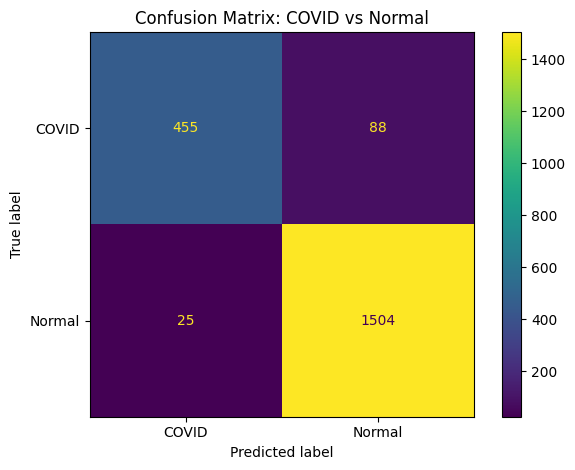

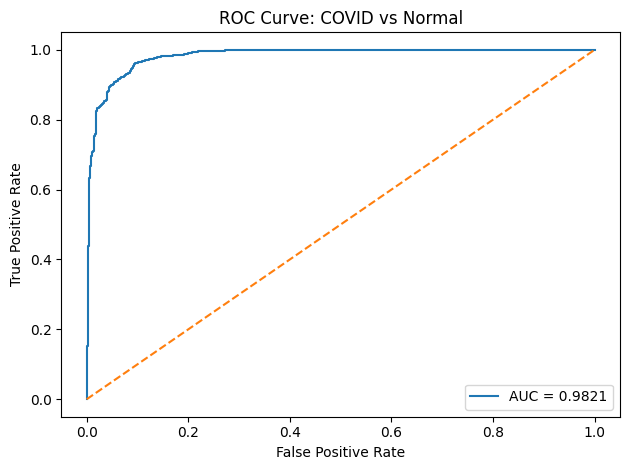

تم حفظ ملفات النتائج في: /content/drive/MyDrive/chest_xray_research


,Test images,Accuracy,Normal precision,Normal recall,Normal F1,COVID recall,ROC-AUC
0,2072,0.945463,0.944724,0.983649,0.963794,0.837937,0.982102


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, classification_report,
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

# تأكد أن خلية التقييم السابقة أنشأت y_true و y_prob
if "y_true" not in globals() or "y_prob" not in globals():
    raise ValueError("شغّل خلية التقييم السابقة أولاً.")

y_true_arr = np.asarray(y_true).astype(int).ravel()
y_prob_arr = np.asarray(y_prob).astype(float).ravel()
y_pred_arr = (y_prob_arr >= 0.5).astype(int)

out_dir = "/content/drive/MyDrive/chest_xray_research"
os.makedirs(out_dir, exist_ok=True)

# 1. تقرير النتائج
report = classification_report(
    y_true_arr, y_pred_arr,
    labels=[0, 1],
    target_names=["COVID", "Normal"],
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    f"{out_dir}/classification_report.csv"
)

# 2. ملخص المقاييس
metrics = pd.DataFrame([{
    "Test images": len(y_true_arr),
    "Accuracy": accuracy_score(y_true_arr, y_pred_arr),
    "Normal precision": precision_score(
        y_true_arr, y_pred_arr, pos_label=1, zero_division=0
    ),
    "Normal recall": recall_score(
        y_true_arr, y_pred_arr, pos_label=1, zero_division=0
    ),
    "Normal F1": f1_score(
        y_true_arr, y_pred_arr, pos_label=1, zero_division=0
    ),
    "COVID recall": recall_score(
        y_true_arr, y_pred_arr, pos_label=0, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_true_arr, y_prob_arr)
}])

metrics.to_csv(f"{out_dir}/summary_metrics.csv", index=False)

# 3. مصفوفة الالتباس
cm = confusion_matrix(y_true_arr, y_pred_arr, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["COVID", "Normal"]
)
disp.plot(values_format="d")
plt.title("Confusion Matrix: COVID vs Normal")
plt.tight_layout()
plt.savefig(f"{out_dir}/confusion_matrix.png", dpi=300)
plt.show()

# 4. منحنى ROC
fpr, tpr, _ = roc_curve(y_true_arr, y_prob_arr, pos_label=1)
roc_auc_value = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_value:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: COVID vs Normal")
plt.legend()
plt.tight_layout()
plt.savefig(f"{out_dir}/roc_curve.png", dpi=300)
plt.show()

print("تم حفظ ملفات النتائج في:", out_dir)
display(metrics)

# New Section